# **Baseline TFT Model for (Temporal) Timeseries Data**
This notebook trains a TFT Model using synthetic timeseries data with its default parameters (no fine-tuning)

In [42]:
import torch
import numpy as np
import pandas as pd
import sklearn as sk
import lightning.pytorch as pl
import matplotlib.pyplot as plt
import pytorch_forecasting as pf
from pytorch_forecasting.metrics import CrossEntropy

In [66]:
RANDOM_SEED = 42
STATIC_DATASET_PATH = '../datasets/static_clinical_data.csv'
TEMPORAL_DATASET_PATH = '../datasets/timeseries_vital_signs.csv'
MODEL_PATH = '../models/baseline_tft_model.ckpt'
TARGET_COLUMN = 'has_sepsis'

## **Data Preparation and Preprocessing**

In [3]:
static_dataset = pd.read_csv(STATIC_DATASET_PATH)
temporal_dataset = pd.read_csv(TEMPORAL_DATASET_PATH)

In [4]:
dataset = temporal_dataset.merge(static_dataset[['patient_id', 'has_sepsis']], on='patient_id', how='left')
del static_dataset
del temporal_dataset
dataset.shape

(122832, 8)

In [5]:
dataset.isnull().sum()

patient_id                  0
hour                        0
heart_rate_bpm          14807
respiratory_rate_rpm    14484
temp_celsius            14523
spo2_pct                14772
map_mmhg                14772
has_sepsis                  0
dtype: int64

In [6]:
incomplete_columns = dataset.columns[dataset.isnull().any()].tolist()
global_means = dataset[incomplete_columns].mean()

for col in incomplete_columns:
    patient_means = dataset.groupby('patient_id')[col].transform('mean')
    dataset[col] = dataset[col].fillna(patient_means)
    dataset[col] = dataset[col].fillna(global_means[col])
	
dataset.isnull().sum()

patient_id              0
hour                    0
heart_rate_bpm          0
respiratory_rate_rpm    0
temp_celsius            0
spo2_pct                0
map_mmhg                0
has_sepsis              0
dtype: int64

In [7]:
dataset.head()

,patient_id,hour,heart_rate_bpm,respiratory_rate_rpm,temp_celsius,spo2_pct,map_mmhg,has_sepsis
0,0,0,152.583105,47.213392,37.044208,93.067937,42.975207,1
1,0,1,149.833800,55.564360,37.208114,93.159351,40.444051,1
2,0,2,154.400023,39.685882,36.847001,92.816919,39.985324,1
3,0,3,142.310062,45.988511,36.556143,94.356813,38.652023,1
4,0,4,158.492857,46.826993,36.779754,97.701063,37.317420,1


In [8]:
dataset.describe()

,patient_id,hour,heart_rate_bpm,respiratory_rate_rpm,temp_celsius,spo2_pct,map_mmhg,has_sepsis
count,122832.0000,122832.00000,122832.000000,122832.000000,122832.000000,122832.000000,122832.000000,122832.000000
mean,852.5000,35.50000,146.228664,47.455634,36.950022,94.994702,41.504112,0.331184
std,492.4817,20.78269,11.943380,7.553776,0.341977,2.338412,4.956700,0.470641
min,0.0000,0.00000,92.478279,13.804312,35.332809,84.607645,18.740116,0.000000
25%,426.0000,17.75000,138.822724,42.755667,36.738909,93.560286,38.440319,0.000000
50%,852.5000,35.50000,146.232492,47.439446,36.950773,94.990062,41.511606,0.000000
75%,1279.0000,53.25000,153.548447,52.120989,37.160910,96.436364,44.553797,1.000000
max,1705.0000,71.00000,200.484817,83.264046,38.379436,106.688890,65.206472,1.000000


In [38]:
patient_targets = dataset[['patient_id', TARGET_COLUMN]].drop_duplicates('patient_id')
train_patients, test_patients = sk.model_selection.train_test_split(
	patient_targets,
	test_size=0.2,
	random_state=RANDOM_SEED,
	stratify=patient_targets[TARGET_COLUMN],
)
train_data = dataset[dataset['patient_id'].isin(train_patients['patient_id'])].copy()
test_data = dataset[dataset['patient_id'].isin(test_patients['patient_id'])].copy()
train_data.shape, test_data.shape

((98208, 8), (24624, 8))

In [39]:
train_data = pf.TimeSeriesDataSet(
	train_data,
	time_idx='hour',
	target=TARGET_COLUMN,
	group_ids=['patient_id'],
	min_encoder_length=12,
	max_encoder_length=12,
	min_prediction_length=1,
	max_prediction_length=1,
	time_varying_unknown_reals=['heart_rate_bpm', 'respiratory_rate_rpm', 'temp_celsius', 'spo2_pct', 'map_mmhg'],
	allow_missing_timesteps=True,
)

test_data = pf.TimeSeriesDataSet.from_dataset(train_data, test_data, predict=True, stop_randomization=True)

In [11]:
train_dataloader = train_data.to_dataloader(batch_size=64, shuffle=True)
test_dataloader = test_data.to_dataloader(batch_size=64, shuffle=False, drop_last=False)

## **Model Setup and Training**

In [43]:
tft = pf.models.TemporalFusionTransformer.from_dataset(
	train_data,
	learning_rate=0.03,
	hidden_size=32,
	attention_head_size=2,
	dropout=0.1,
	output_size=2,
	loss=CrossEntropy(),
)
print(f'Number of parameters in TFT: {tft.size():,}')

Number of parameters in TFT: 58,354


/home/tacs/projects/pal.se/notebooks/.venv/lib/python3.14/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
/home/tacs/projects/pal.se/notebooks/.venv/lib/python3.14/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.


In [41]:
trainer = pl.Trainer(
    max_epochs=5,
    accelerator='auto',
)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [44]:
trainer.fit(tft, train_dataloaders=train_dataloader, val_dataloaders=test_dataloader)

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.

   | Name                               | Type                            | Params | Mode  | FLOPs
--------------------------------------------------------------------------------------------------------
0  | loss                               | CrossEntropy                    | 0      | train | 0    
1  | logging_metrics                    | ModuleList                      | 0      | train | 0    
2  | input_embeddings                   | MultiEmbedding                  | 0      | train | 0    
3  | prescalers                         | ModuleDict                      | 80     | train | 0    
4  | static_variable_selection          | VariableSelectionNetwork        | 0      | train | 0    
5  | encoder_variable_selection         | VariableSelectionNetwork        | 5.0 K  | train | 0 

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/tacs/projects/pal.se/notebooks/.venv/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/tacs/projects/pal.se/notebooks/.venv/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.
/home/tacs/projects/pal.se/notebooks/.venv/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=5` reached.


## **Baseline Model Evaluation**

In [45]:
results = tft.predict(test_dataloader, mode='raw', return_y=True)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
/home/tacs/projects/pal.se/notebooks/.venv/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


In [46]:
y_pred_logits = results.output.prediction.detach().cpu()
y_pred = torch.softmax(y_pred_logits, dim=-1)[..., 1].numpy()
y_true = results.y[0].detach().cpu().numpy()

print(f'Predictions: {y_pred.shape}')
print(f'Actuals: {y_true.shape}')
print(f'Actual positive rate: {y_true.mean():.3f}')
print(f'Predicted probability range: {y_pred.min():.4f} to {y_pred.max():.4f}')

Predictions: (351, 1)
Actuals: (351, 1)
Actual positive rate: 0.330
Predicted probability range: 0.3143 to 0.3143


In [62]:
mse = np.mean((y_pred - y_true) ** 2)
rmse = np.sqrt(mse)
wape = np.sum(np.abs(y_pred - y_true)) / np.sum(np.abs(y_true))
r2 = sk.metrics.r2_score(y_true, y_pred)

print(f'MSE: {mse:.4f}')
print(f'RMSE: {rmse:.4f}')
print(f'WAPE: {wape:.4f}')
print(f'R^2: {r2:.4f}')

MSE: 0.2215
RMSE: 0.4707
WAPE: 1.3225
R^2: -0.0012


In [65]:
y_pred_binary = (y_pred >= 0.5).astype(int)

accuracy = sk.metrics.accuracy_score(y_true, y_pred_binary)
precision = sk.metrics.precision_score(y_true, y_pred_binary)
recall = sk.metrics.recall_score(y_true, y_pred_binary)
f1 = sk.metrics.f1_score(y_true, y_pred_binary)

print(f'Accuracy: {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'F1 Score: {f1:.4f}')

Accuracy: 0.6695
Precision: 0.0000
Recall: 0.0000
F1 Score: 0.0000


/home/tacs/projects/pal.se/notebooks/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


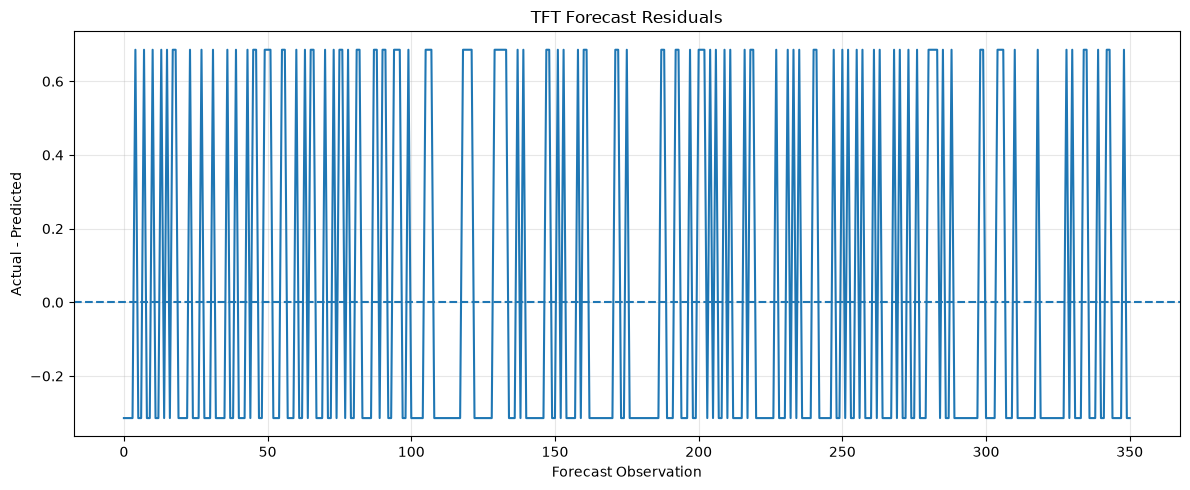

In [58]:
actual = y_true.reshape(-1)
predicted = y_pred.reshape(-1)
residuals = actual - predicted

plt.figure(figsize=(12, 5))
plt.plot(residuals)
plt.axhline(0, linestyle="--")

plt.title("TFT Forecast Residuals")
plt.xlabel("Forecast Observation")
plt.ylabel("Actual - Predicted")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

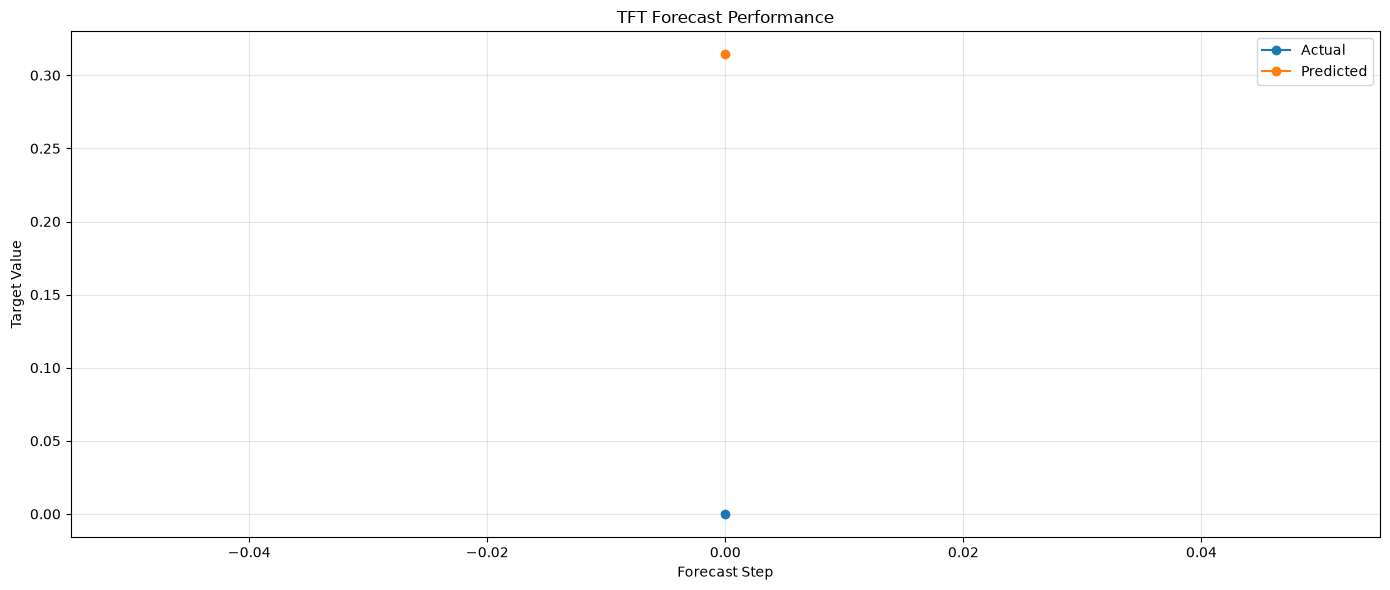

In [60]:
plt.figure(figsize=(14, 6))

plt.plot(
    y_true[0],
    label="Actual",
    marker="o",
)
plt.plot(
    y_pred[0],
    label="Predicted",
    marker="o",
)

plt.title("TFT Forecast Performance")
plt.xlabel("Forecast Step")
plt.ylabel("Target Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## **Exporting the Model**

In [67]:
trainer.save_checkpoint(MODEL_PATH)

`weights_only` was not set, defaulting to `False`.
